# Does Receiver Residual Repeatability Hold Within 2023?

The previous cross-season audit found modest receiver-level residual persistence, but it was uncertain and sensitive to cohort choice. This diagnostic isolates within-season repeatability: keep every 2023 route's dynamic Ridge residual fixed, repeatedly split whole games into two balanced-by-week halves, and correlate each receiver's average residual between halves.

These residuals come from the dynamic model frozen on 2021. The 10th–90th percentile range reflects sensitivity to how games are assigned to halves. The pooled 95% intervals combine repeated game assignments with bootstrap samples of eligible receivers. Neither interval is a causal estimate of receiver skill.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from IPython.display import HTML, SVG, display
from separation_over_expected.reports import read_csv_rows, write_csv
from separation_over_expected.within_season_reliability import (
    DEFAULT_COHORTS,
    evaluate_within_season_receiver_reliability,
)

PREDICTIONS = PROJECT_ROOT / "data/processed/cross_season_receiver_reliability/route_predictions.csv"
CROSS_SEASON_METRICS = PROJECT_ROOT / "data/processed/cross_season_receiver_reliability/reliability_metrics.csv"
OUTPUT = PROJECT_ROOT / "data/processed/within_season_receiver_reliability"
if not PREDICTIONS.exists() or not CROSS_SEASON_METRICS.exists():
    raise FileNotFoundError(
        "Run notebook 17 or `uv run separation-over-expected cross-season-receiver-reliability` first."
    )

predictions = read_csv_rows(PREDICTIONS)
predictions_2023 = [row for row in predictions if row["season"] == "2023"]
len(predictions_2023), len({row["gameId"] for row in predictions_2023})

(38002, 272)

## Repeated whole-game splits

Games are assigned to A/B separately within each week, so both halves cover the season. Receiver eligibility is enforced independently in each half. The thresholds include the main 20-route/five-game reference and looser/stricter checks. A correlation is omitted for any split with fewer than three eligible receivers.

In [2]:
split_rows, summary_rows = evaluate_within_season_receiver_reliability(
    predictions,
    cohorts=DEFAULT_COHORTS,
    split_seeds=100,
    bootstrap_samples=500,
    seed=42,
)
OUTPUT.mkdir(parents=True, exist_ok=True)
write_csv(OUTPUT / "split_results.csv", list(split_rows[0]), split_rows)
write_csv(OUTPUT / "reliability_summary.csv", list(summary_rows[0]), summary_rows)

cross_season = next(
    row for row in read_csv_rows(CROSS_SEASON_METRICS)
    if row["comparison"] == "dynamic"
)

def fmt_interval(lower, upper):
    return f"[{float(lower):.2f}, {float(upper):.2f}]"

table_rows = []
for row in summary_rows:
    table_rows.append({
        "routes / games per half": f'{row["min_routes_per_half"]} / {row["min_games_per_half"]}',
        "median eligible receivers": round(float(row["receivers_median"]), 1),
        "Pearson median (split P10–P90)": (
            f'{float(row["pearson_median"]):.2f} '
            f'({fmt_interval(row["pearson_p10"], row["pearson_p90"])})'
        ),
        "Pearson pooled bootstrap 95% interval": fmt_interval(
            row["pearson_bootstrap_ci_lower"], row["pearson_bootstrap_ci_upper"]
        ),
        "Spearman median (split P10–P90)": (
            f'{float(row["spearman_median"]):.2f} '
            f'({fmt_interval(row["spearman_p10"], row["spearman_p90"])})'
        ),
        "Spearman pooled bootstrap 95% interval": fmt_interval(
            row["spearman_bootstrap_ci_lower"], row["spearman_bootstrap_ci_upper"]
        ),
    })
display(table_rows)

[{'routes / games per half': '10 / 3',
  'median eligible receivers': 161.0,
  'Pearson median (split P10–P90)': '0.23 ([0.12, 0.33])',
  'Pearson pooled bootstrap 95% interval': '[-0.02, 0.46]',
  'Spearman median (split P10–P90)': '0.22 ([0.14, 0.29])',
  'Spearman pooled bootstrap 95% interval': '[0.02, 0.41]'},
 {'routes / games per half': '20 / 5',
  'median eligible receivers': 115.0,
  'Pearson median (split P10–P90)': '0.27 ([0.13, 0.37])',
  'Pearson pooled bootstrap 95% interval': '[-0.00, 0.49]',
  'Spearman median (split P10–P90)': '0.27 ([0.16, 0.36])',
  'Spearman pooled bootstrap 95% interval': '[0.02, 0.48]'},
 {'routes / games per half': '30 / 5',
  'median eligible receivers': 108.0,
  'Pearson median (split P10–P90)': '0.30 ([0.19, 0.39])',
  'Pearson pooled bootstrap 95% interval': '[0.04, 0.52]',
  'Spearman median (split P10–P90)': '0.30 ([0.19, 0.38])',
  'Spearman pooled bootstrap 95% interval': '[0.04, 0.50]'}]

## Compare with the cross-season result

The dashed reference lines show the earlier dynamic cross-season estimate under the 20-route/five-game-per-season cohort, with its nested bootstrap interval shaded. That comparison is directional: the within-season eligibility rule applies per half, so the number and composition of eligible receivers differ. Blue bars show pooled receiver-bootstrap intervals; lighter whiskers show point-estimate sensitivity across game assignments.

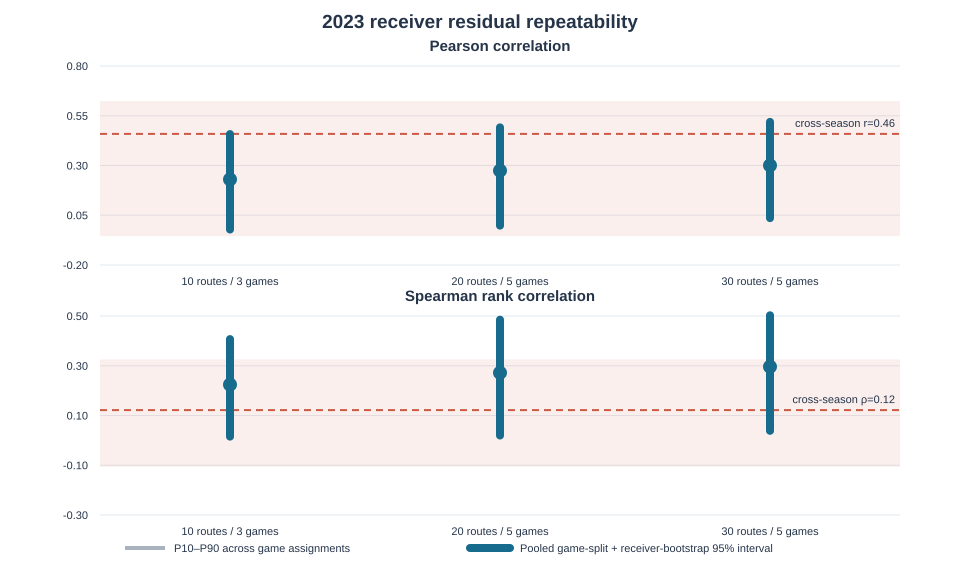

In [3]:
def reliability_svg(summaries, cross, width=960, height=570):
    panels = [
        ("pearson", "Pearson correlation", float(cross["pearson"]), float(cross["pearson_ci_lower"]), float(cross["pearson_ci_upper"]), -0.2, 0.8),
        ("spearman", "Spearman rank correlation", float(cross["spearman"]), float(cross["spearman_ci_lower"]), float(cross["spearman_ci_upper"]), -0.3, 0.5),
    ]
    left, right, top, bottom = 100, 900, 66, 265
    xs = [230, 500, 770]
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,sans-serif;fill:#253449}.grid{stroke:#e4e9ef}.assign{stroke:#7b8b99;stroke-width:4;opacity:.65}.boot{stroke:#176c8d;stroke-width:8;stroke-linecap:round}.ref{stroke:#c85b48;stroke-width:2;stroke-dasharray:7 5}</style>',
        '<text x="480" y="28" text-anchor="middle" font-size="19" font-weight="bold">2023 receiver residual repeatability</text>',
    ]
    for panel_index, (metric, title, ref_value, ref_low, ref_high, ymin, ymax) in enumerate(panels):
        y_top = top + panel_index * 250
        y_bottom = bottom + panel_index * 250
        yscale = lambda value: y_bottom - (float(value) - ymin) / (ymax - ymin) * (y_bottom - y_top)
        parts.append(f'<text x="500" y="{y_top-15}" text-anchor="middle" font-size="15" font-weight="bold">{title}</text>')
        for tick_i in range(5):
            value = ymin + (ymax - ymin) * tick_i / 4
            yy = yscale(value)
            parts.extend([
                f'<line class="grid" x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}"/>',
                f'<text x="{left-12}" y="{yy+4:.1f}" text-anchor="end" font-size="11">{value:.2f}</text>',
            ])
        band_top, band_bottom = sorted((yscale(ref_low), yscale(ref_high)))
        parts.append(f'<rect x="{left}" y="{band_top:.1f}" width="{right-left}" height="{band_bottom-band_top:.1f}" fill="#c85b48" fill-opacity=".10"/>')
        parts.append(f'<line class="ref" x1="{left}" y1="{yscale(ref_value):.1f}" x2="{right}" y2="{yscale(ref_value):.1f}"/>')
        for x, row in zip(xs, summaries):
            median = float(row[f"{metric}_median"])
            low, high = float(row[f"{metric}_p10"]), float(row[f"{metric}_p90"])
            ci_low = float(row[f"{metric}_bootstrap_ci_lower"])
            ci_high = float(row[f"{metric}_bootstrap_ci_upper"])
            parts.extend([
                f'<line class="assign" x1="{x}" y1="{yscale(low):.1f}" x2="{x}" y2="{yscale(high):.1f}"/>',
                f'<line class="boot" x1="{x}" y1="{yscale(ci_low):.1f}" x2="{x}" y2="{yscale(ci_high):.1f}"/>',
                f'<circle cx="{x}" cy="{yscale(median):.1f}" r="7" fill="#176c8d"/>',
                f'<text x="{x}" y="{y_bottom+20}" text-anchor="middle" font-size="11">{row["min_routes_per_half"]} routes / {row["min_games_per_half"]} games</text>',
            ])
        if panel_index == 0:
            parts.append(f'<text x="{right-5}" y="{yscale(ref_value)-7:.1f}" text-anchor="end" font-size="11" fill="#a44b3b">cross-season r={ref_value:.2f}</text>')
        else:
            parts.append(f'<text x="{right-5}" y="{yscale(ref_value)-7:.1f}" text-anchor="end" font-size="11" fill="#a44b3b">cross-season ρ={ref_value:.2f}</text>')
    parts.extend([
        '<line class="assign" x1="125" y1="548" x2="165" y2="548"/><text x="174" y="552" font-size="11">P10–P90 across game assignments</text>',
        '<line class="boot" x1="470" y1="548" x2="510" y2="548"/><text x="520" y="552" font-size="11">Pooled game-split + receiver-bootstrap 95% interval</text>',
        '</svg>',
    ])
    return ''.join(parts)

display(SVG(reliability_svg(summary_rows, cross_season)))

## Readout

Compare the within-2023 point estimates, assignment ranges, and receiver-bootstrap intervals with the cross-season estimates. Strong within-season repeatability alongside weak cross-season repeatability would implicate season-to-season measurement or role changes as plausible contributors. Weak repeatability both within and across seasons would suggest that receiver-average residuals are noisy under the current definition. Either outcome is diagnostic, not proof of the cause.

At the primary 20-route/five-game threshold, within-2023 median Pearson repeatability is 0.274 (assignment P10–P90: 0.130–0.368), with a pooled 95% bootstrap interval of approximately [-0.00, 0.49]. The cross-season point estimate is higher at 0.459, but its interval is also broad and includes zero. We therefore do not have evidence that the signal is clearly stronger within a season or that cross-season measurement mismatch is the main problem. The current receiver-level residual remains modest and uncertain.

In [4]:
main_cohort = next(
    row for row in summary_rows
    if row["min_routes_per_half"] == "20" and row["min_games_per_half"] == "5"
)
readout = {
    "2023 routes scored": len(predictions_2023),
    "2023 games": len({row["gameId"] for row in predictions_2023}),
    "game assignments": 100,
    "main cohort median receivers": round(float(main_cohort["receivers_median"]), 1),
    "within-2023 median Pearson": round(float(main_cohort["pearson_median"]), 3),
    "within-2023 assignment P10–P90": (
        round(float(main_cohort["pearson_p10"]), 3),
        round(float(main_cohort["pearson_p90"]), 3),
    ),
    "cross-season Pearson": float(cross_season["pearson"]),
    "cross-season 95% interval": (
        float(cross_season["pearson_ci_lower"]),
        float(cross_season["pearson_ci_upper"]),
    ),
}
readout

{'2023 routes scored': 38002,
 '2023 games': 272,
 'game assignments': 100,
 'main cohort median receivers': 115.0,
 'within-2023 median Pearson': 0.274,
 'within-2023 assignment P10–P90': (0.13, 0.368),
 'cross-season Pearson': 0.458604,
 'cross-season 95% interval': (-0.054859, 0.623548)}